In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

import joblib

%matplotlib inline

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [3]:
PROJECT_DIR = Path.cwd().parent

OUTPUT_DIR = PROJECT_DIR / "outputs"

print("Output directory:", OUTPUT_DIR)

Output directory: d:\spamEmail\unsaturated\outputs


In [4]:
X_reduced = np.load(OUTPUT_DIR / "X_reduced.npy")

y_true = np.load(OUTPUT_DIR / "y_true.npy")

kmeans_labels = np.load(
    OUTPUT_DIR / "kmeans_labels.npy"
)

dbscan_labels = np.load(
    OUTPUT_DIR / "dbscan_labels.npy"
)

isolation_labels = np.load(
    OUTPUT_DIR / "isolation_forest_labels.npy"
)

dbscan_sample_indices = np.load(
    OUTPUT_DIR / "dbscan_sample_indices.npy"
)

print("All saved results loaded successfully!")

All saved results loaded successfully!


In [5]:
print("Total emails:", len(y_true))

print("K-Means predictions:", len(kmeans_labels))
print("DBSCAN predictions:", len(dbscan_labels))
print("Isolation Forest predictions:", len(isolation_labels))

print("DBSCAN sample size:", len(dbscan_sample_indices))

Total emails: 108671
K-Means predictions: 108671
DBSCAN predictions: 10000
Isolation Forest predictions: 108671
DBSCAN sample size: 10000


In [ ]:
kmeans_ari = adjusted_rand_score(
    y_true,
    kmeans_labels
)

kmeans_nmi = normalized_mutual_info_score(
    y_true,
    kmeans_labels
)

kmeans_silhouette = silhouette_score(
    X_reduced,
    kmeans_labels,
    sample_size=10000,
    random_state=RANDOM_STATE
)

print("K-Means ARI:", round(kmeans_ari, 4))
print("K-Means NMI:", round(kmeans_nmi, 4))
print("K-Means Silhouette:", round(kmeans_silhouette, 4))

K-Means ARI: 0.0754
K-Means NMI: 0.0591
K-Means Silhouette: 0.3321


In [7]:
y_dbscan_sample = y_true[dbscan_sample_indices]

dbscan_ari = adjusted_rand_score(
    y_dbscan_sample,
    dbscan_labels
)

dbscan_nmi = normalized_mutual_info_score(
    y_dbscan_sample,
    dbscan_labels
)

print("DBSCAN ARI:", round(dbscan_ari, 4))
print("DBSCAN NMI:", round(dbscan_nmi, 4))

DBSCAN ARI: 0.1295
DBSCAN NMI: 0.1936


In [8]:
isolation_ari = adjusted_rand_score(
    y_true,
    isolation_labels
)

isolation_nmi = normalized_mutual_info_score(
    y_true,
    isolation_labels
)

print("Isolation Forest ARI:", round(isolation_ari, 4))
print("Isolation Forest NMI:", round(isolation_nmi, 4))

Isolation Forest ARI: 0.0009
Isolation Forest NMI: 0.0007


In [9]:
comparison_results = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Dataset Size": len(y_true),
        "ARI": kmeans_ari,
        "NMI": kmeans_nmi,
        "Silhouette": kmeans_silhouette
    },
    {
        "Algorithm": "DBSCAN",
        "Dataset Size": len(y_dbscan_sample),
        "ARI": dbscan_ari,
        "NMI": dbscan_nmi,
        "Silhouette": np.nan
    },
    {
        "Algorithm": "Isolation Forest",
        "Dataset Size": len(y_true),
        "ARI": isolation_ari,
        "NMI": isolation_nmi,
        "Silhouette": np.nan
    }
])

comparison_results.round(4)

,Algorithm,Dataset Size,ARI,NMI,Silhouette
0,K-Means,108671,0.0754,0.0591,0.3321
1,DBSCAN,10000,0.1295,0.1936,NaN
2,Isolation Forest,108671,0.0009,0.0007,NaN


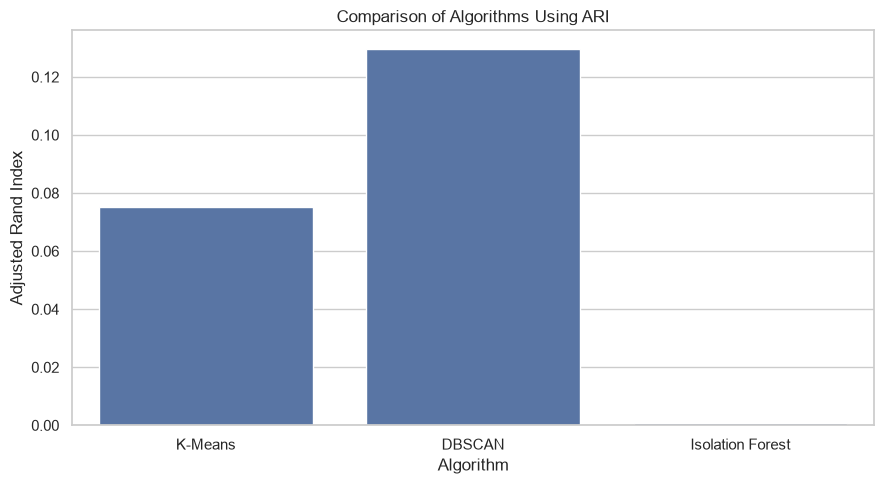

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_results,
    x="Algorithm",
    y="ARI"
)

plt.title("Comparison of Algorithms Using ARI")
plt.xlabel("Algorithm")
plt.ylabel("Adjusted Rand Index")

plt.tight_layout()
plt.show()

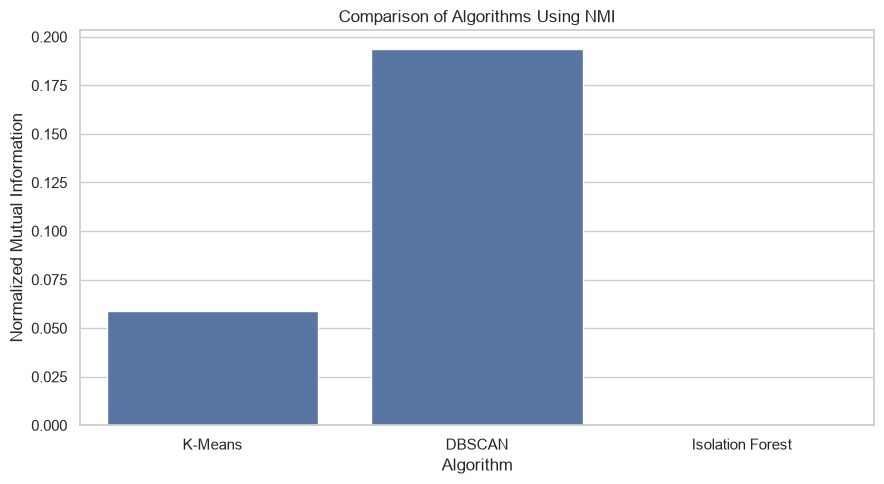

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_results,
    x="Algorithm",
    y="NMI"
)

plt.title("Comparison of Algorithms Using NMI")
plt.xlabel("Algorithm")
plt.ylabel("Normalized Mutual Information")

plt.tight_layout()
plt.show()

In [12]:
kmeans_cluster_count = len(np.unique(kmeans_labels))

dbscan_cluster_count = len(
    set(dbscan_labels) - {-1}
)

isolation_anomaly_count = np.sum(
    isolation_labels == 1
)

algorithm_counts = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "DBSCAN",
        "Isolation Forest"
    ],
    "Groups or Anomalies": [
        kmeans_cluster_count,
        dbscan_cluster_count,
        isolation_anomaly_count
    ]
})

algorithm_counts

,Algorithm,Groups or Anomalies
0,K-Means,2
1,DBSCAN,57
2,Isolation Forest,716


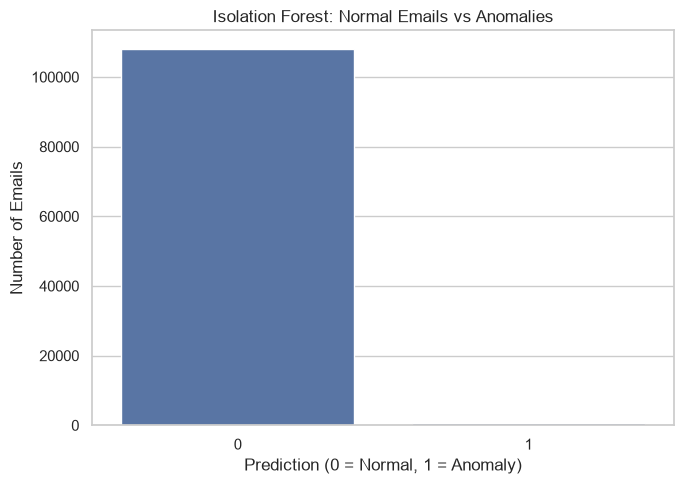

In [13]:
anomaly_counts = pd.Series(
    isolation_labels
).value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=anomaly_counts.index.astype(str),
    y=anomaly_counts.values
)

plt.title("Isolation Forest: Normal Emails vs Anomalies")
plt.xlabel("Prediction (0 = Normal, 1 = Anomaly)")
plt.ylabel("Number of Emails")

plt.tight_layout()
plt.show()

In [14]:
kmeans_comparison = pd.crosstab(
    pd.Series(y_true, name="Actual Label"),
    pd.Series(kmeans_labels, name="K-Means Cluster")
)

kmeans_comparison

K-Means Cluster,0,1
Actual Label,,
0.0,36359,24278
1.0,15138,32896


In [15]:
dbscan_comparison = pd.crosstab(
    pd.Series(y_dbscan_sample, name="Actual Label"),
    pd.Series(dbscan_labels, name="DBSCAN Cluster")
)

dbscan_comparison

DBSCAN Cluster,-1,0,1,2,3,4,5,6,7,8,...,47,48,49,50,51,52,53,54,55,56
Actual Label,,,,,,,,,,,,,,,,,,,,,
0.0,657,2514,501,13,0,4,46,4,972,97,...,0,0,0,0,12,6,17,0,11,10
1.0,877,88,525,599,11,310,419,193,581,87,...,10,17,12,10,0,4,0,15,0,0


In [16]:
isolation_comparison = pd.crosstab(
    pd.Series(y_true, name="Actual Label"),
    pd.Series(isolation_labels, name="Isolation Forest Prediction")
)

isolation_comparison

Isolation Forest Prediction,0,1
Actual Label,,
0.0,60336,301
1.0,47619,415


In [17]:
comparison_results.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

algorithm_counts.to_csv(
    OUTPUT_DIR / "algorithm_group_comparison.csv",
    index=False
)

kmeans_comparison.to_csv(
    OUTPUT_DIR / "final_kmeans_comparison.csv"
)

dbscan_comparison.to_csv(
    OUTPUT_DIR / "final_dbscan_comparison.csv"
)

isolation_comparison.to_csv(
    OUTPUT_DIR / "final_isolation_comparison.csv"
)

print("Final comparison results saved successfully!")

Final comparison results saved successfully!


In [18]:
print("FINAL MODEL COMPARISON")
print("======================")

print("\nK-MEANS")
print("ARI:", round(kmeans_ari, 4))
print("NMI:", round(kmeans_nmi, 4))
print("Silhouette:", round(kmeans_silhouette, 4))

print("\nDBSCAN")
print("ARI:", round(dbscan_ari, 4))
print("NMI:", round(dbscan_nmi, 4))
print("Sample size:", len(y_dbscan_sample))

print("\nISOLATION FOREST")
print("ARI:", round(isolation_ari, 4))
print("NMI:", round(isolation_nmi, 4))
print("Anomalies:", isolation_anomaly_count)

print("\nAll comparisons completed!")

FINAL MODEL COMPARISON

K-MEANS
ARI: 0.0754
NMI: 0.0591
Silhouette: 0.3321

DBSCAN
ARI: 0.1295
NMI: 0.1936
Sample size: 10000

ISOLATION FOREST
ARI: 0.0009
NMI: 0.0007
Anomalies: 716

All comparisons completed!
